# Delivery-time regression at carrier handover
## Model selection and operational decision support

This working checkpoint examines two questions:
1. Does regularisation improve the handover forecast sufficiently to justify ridge over plain linear regression?
2. Can the forecast help operations identify parcels worth reviewing before their promised date expires?

The notebook calculates paired comparisons, refits the extended ridge grid, and evaluates next-morning review queues. The existing promise remains unchanged. Classification estimates lateness risk; regression supplies an estimate of time remaining and the shortfall against that promise.

**Evidence boundary.** The historical validation and test periods have been used previously. The extensions are descriptive follow-up analyses, not a new independent test. Hypothetical speed-ups are scenario assumptions, not measured carrier effects.


## 1. Data and evaluation design

The submitted Phase 2 package builds one row per delivered order and restricts the comparison to valid purchase–handover–delivery sequences. Five chronological validation windows use only fitting outcomes known before each window starts. Preprocessing is fitted inside each model pipeline, and route history uses only earlier completed deliveries [1, 2].

Run all cells using the dependencies in `requirements.txt`. The setup locates the repository from either its root or this notebook's folder. The fitting cell regenerates the handover results; it leaves Phase 2 outputs unchanged.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Phase2/phase2_eta.py').is_file())
WORK = ROOT / 'Phase3/handover'
RESULTS = WORK / 'results'
sys.path.insert(0, str(WORK))
sys.path.insert(0, str(ROOT / 'Phase2'))
from analyse import run, paired_comparison, decision_rows, rank_queue, queue_metrics
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
spec = json.loads((ROOT / 'Phase2/data/phase2_feature_spec.json').read_text())
display(pd.Series({k: spec[k] for k in ['primary_cutoff', 'n_folds', 'validation_maturity_days', 'random_state']}, name='Setting').to_frame())


,Setting
primary_cutoff,2018-05-26
n_folds,5
validation_maturity_days,60
random_state,42


## 2. Feedback: ridge versus plain linear regression

For each window, calculate `gain = MAE(linear) − MAE(ridge)`. Positive gains favour ridge. The paired standard error is `SD(gain) / sqrt(number of windows)`.

Under the project's adapted one-SE comparison, plain linear is retained when its mean disadvantage is no greater than the paired standard error. This is a model-selection heuristic, not a significance test: the five windows have overlapping fitting histories [1, 2].


,stage,window,linear_mae,ridge_mae,gain_days
0,checkout,1,3.99868,3.97140,0.02728
1,checkout,2,6.70610,6.66248,0.04362
2,checkout,3,5.39736,5.33568,0.06168
3,checkout,4,5.90389,5.83157,0.07232
4,checkout,5,7.29552,7.24154,0.05398
5,handover,1,3.36901,3.31989,0.04913
6,handover,2,5.79517,5.73895,0.05622
7,handover,3,4.68724,4.63891,0.04833
8,handover,4,5.21706,5.16499,0.05207
9,handover,5,6.66252,6.63007,0.03245


,mean_gain_days,sd_gain_days,paired_se_days,plain_within_one_se
stage,,,,
checkout,0.05178,0.01726,0.00772,False
handover,0.04764,0.00904,0.00404,False


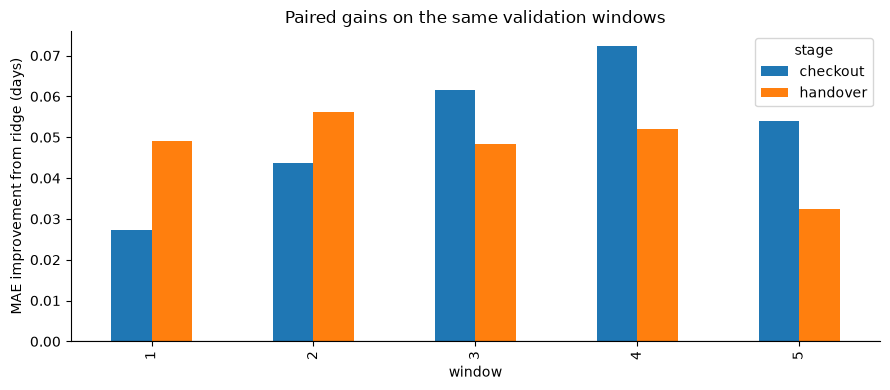

In [2]:
submitted = pd.read_csv(ROOT / 'Phase2/results/phase2/eta/cv_metrics.csv')
paired_rows, window_rows = [], []
for stage in ['checkout', 'handover']:
    p = submitted[submitted.stage.eq(stage)].pivot(index='window', columns='candidate', values='mae')
    gain = p.linear_baseline - p.ridge_100
    result = paired_comparison(p.linear_baseline, p.ridge_100)
    paired_rows.append({'stage': stage, **{k: v for k, v in result.items() if k != 'window_gains_days'}})
    window_rows.extend({'stage': stage, 'window': int(w)+1, 'linear_mae': p.loc[w, 'linear_baseline'],
                        'ridge_mae': p.loc[w, 'ridge_100'], 'gain_days': g} for w, g in gain.items())
display(pd.DataFrame(window_rows).round(5))
paired = pd.DataFrame(paired_rows).set_index('stage')
display(paired.round(5))
ax = pd.DataFrame(window_rows).pivot(index='window', columns='stage', values='gain_days').plot.bar()
ax.set(ylabel='MAE improvement from ridge (days)', title='Paired gains on the same validation windows')
ax.axhline(0, color='black', linewidth=.8)
plt.tight_layout(); plt.show()


**Interpretation.** Plain linear is outside the one-SE margin at both stages. At handover the gain is about 0.048 days, or 69 minutes, with paired SE about 0.004 days. This supports the ridge selection under the stated rule, while the small absolute improvement motivates a separate assessment of operational value. The logistic comparison remains part of the classification analysis.


## 3. Feedback: extend the regularisation grid

The original alpha=100 selection was at the boundary. We now compare plain linear with ridge alpha values 0.01, 0.1, 1, 10, 100, 1,000, 10,000 and 100,000, keeping features and folds fixed.

Within ridge, choose the lowest mean validation MAE. Compare that candidate with plain linear using the paired one-SE rule. The following cell actually runs the fits and regenerates the predictions and queue scenarios through the shared analysis functions. The queue always uses the submitted alpha=100 model, keeping the operational comparison separate from extended-grid selection.


In [3]:
# Keep detailed audit metadata in results/selection_audit.json.
# Capture fitting progress so the notebook presents the decision summary only.
import io
from contextlib import redirect_stdout
with redirect_stdout(io.StringIO()):
    run(ROOT / 'Phase2', RESULTS)
fit_audit = json.loads((RESULTS / 'selection_audit.json').read_text())
fit_comparison = fit_audit['extended_plain_vs_best']
display(pd.Series({
    'Selected model': fit_audit['selected'],
    'Validation MAE gain over plain linear (days)': round(fit_comparison['mean_gain_days'], 5),
    'Paired standard error (days)': round(fit_comparison['paired_se_days'], 5),
    'Evaluation scope': 'Five chronological validation windows; previously examined later period is descriptive'
}, name='Result').to_frame())

,Result
Selected model,ridge_1000
Validation MAE gain over plain linear (days),0.09142
Paired standard error (days),0.01513
Evaluation scope,Five chronological validation windows; previou...


,mae,rmse,r2
candidate,,,
ridge_1000,5.0548,8.3176,0.3509
ridge_100,5.0985,8.4063,0.3376
ridge_10,5.1360,8.4596,0.3292
ridge_10000,5.1422,8.4183,0.3341
ridge_1,5.1448,8.4703,0.3274
ridge_0.1,5.1460,8.4717,0.3271
ridge_0.01,5.1462,8.4718,0.3271
linear,5.1462,8.4718,0.3271
ridge_100000,5.8219,9.2111,0.1983


,linear vs ridge100,linear vs best ridge,ridge100 vs best ridge
mean_gain_days,0.04765,0.09142,0.043771
sd_gain_days,0.009078,0.033825,0.036035
paired_se_days,0.00406,0.015127,0.016115
plain_within_one_se,False,False,False


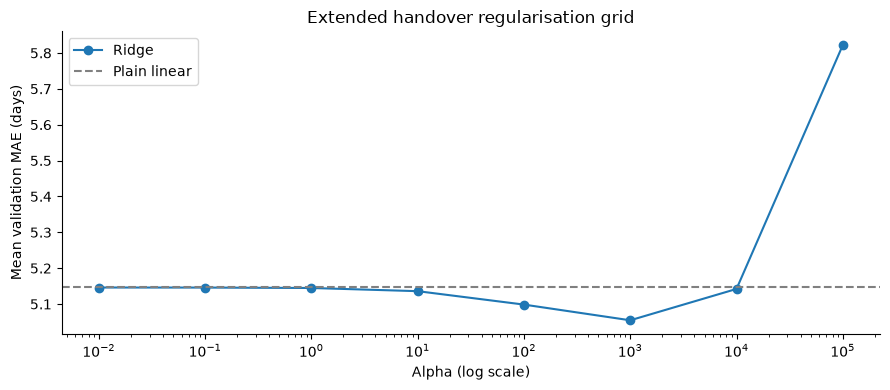

Validation-selected candidate: ridge_1000


In [4]:
grid = pd.read_csv(RESULTS / 'extended_grid_windows.csv')
audit = json.loads((RESULTS / 'selection_audit.json').read_text())
summary = grid.groupby('candidate')[['mae', 'rmse', 'r2']].mean()
display(summary.sort_values('mae').round(4))
p = grid.pivot(index='window', columns='candidate', values='mae')
display(pd.DataFrame({
    'linear vs ridge100': paired_comparison(p.linear, p.ridge_100),
    'linear vs best ridge': paired_comparison(p.linear, p[audit['extended_best_ridge']]),
    'ridge100 vs best ridge': paired_comparison(p.ridge_100, p[audit['extended_best_ridge']])
}).drop(index='window_gains_days'))
ridge = summary.loc[summary.index.str.startswith('ridge_')].copy()
ridge['alpha'] = ridge.index.str.replace('ridge_', '').astype(float)
ridge = ridge.sort_values('alpha')
fig, ax = plt.subplots()
ax.semilogx(ridge.alpha, ridge.mae, marker='o', label='Ridge')
ax.axhline(summary.loc['linear', 'mae'], linestyle='--', color='grey', label='Plain linear')
ax.set(xlabel='Alpha (log scale)', ylabel='Mean validation MAE (days)', title='Extended handover regularisation grid')
ax.legend(); plt.tight_layout(); plt.show()
print('Validation-selected candidate:', audit['selected'])


## 4. Does the validation gain transfer to the later period?

MAE measures average absolute error in days. Signed error is predicted minus actual duration: a positive value means the forecast runs too long. The route rule predicts elapsed days plus the recent route transit mean [2].


In [5]:
metrics = pd.read_csv(RESULTS / 'prediction_metrics.csv')
validation = metrics[metrics.period.str.startswith('validation')].groupby('model')[['mae', 'rmse', 'r2', 'mean_signed_error']].mean()
later = metrics[metrics.period.eq('test_descriptive')].set_index('model')
display(pd.concat({'Validation mean': validation, 'Later period': later[validation.columns]}, names=['evaluation', 'model']).round(4))
display(later[['orders', 'p90_absolute_error', 'negative_remaining']].round(3))


mae    rmse      r2  mean_signed_error
evaluation      model                                                  
Validation mean frozen_ridge  5.0985  8.4063  0.3376            -2.3400
                route_rule    5.3039  8.3960  0.3370            -1.9959
                selected      5.0548  8.3176  0.3509            -2.1675
Later period    frozen_ridge  3.9719  5.4418  0.1535             2.8667
                selected      4.1994  5.6568  0.0854             3.1201
                route_rule    3.7617  5.2409  0.2149             2.4466

,orders,p90_absolute_error,negative_remaining
model,,,
frozen_ridge,19230,8.232,157
selected,19230,8.688,178
route_rule,19230,7.780,0


**Interpretation.** Alpha=1,000 improves validation MAE from approximately 5.099 to 5.055 days, but later-period MAE worsens from 3.972 to 4.199 days. Grid extension does not resolve the generalisation problem. The later-period route rule is also competitive. These results do not justify choosing a new winner using the already-examined test period.

The submitted ridge model has roughly four days of later-period MAE and an 8.2-day 90th-percentile absolute error. These are aggregate diagnostics, not individual prediction intervals. Negative remaining-time predictions for open parcels require explicit handling in an application.


## 5. Translate the forecast into an operational decision

`Predicted arrival = purchase time + predicted total days`

`Estimated remaining time = predicted arrival − review time`

`Time budget = end of promised calendar day − review time`

`Estimated shortfall = estimated remaining time − time budget`

A positive shortfall suggests how much faster the forecast would need to be to meet the promise. It does not establish that an upgrade exists. For example, five predicted days remaining and three days available imply a two-day shortfall.

Review takes place at 09:00 after the handover day. Only open parcels with an unexpired promise enter the prevention queue. The end of the promised calendar day is represented by the following midnight, so delivery during the promised day remains on time. Actual delivery is used only for status known at review and subsequent evaluation, never to rank future outcomes.


In [6]:
dates = ['order_purchase_timestamp', 'handover_time', 'outcome_available_at', 'order_estimated_delivery_date']
pred = pd.read_csv(RESULTS / 'predictions.csv.gz', parse_dates=dates)
decisions = decision_rows(pred)
coverage = decisions.groupby('period').agg(handovers=('order_id', 'size'), open_at_review=('open_at_review', 'sum'),
                                         before_deadline=('before_deadline', 'sum'), eligible=('eligible', 'sum'))
display(coverage)
examples = decisions[decisions.period.eq('test_descriptive') & decisions.eligible].copy()
examples['predicted_arrival'] = examples.order_purchase_timestamp + pd.to_timedelta(examples.frozen_ridge, unit='D')
examples['remaining_days'] = (examples.predicted_arrival - examples.review_time).dt.total_seconds()/86400
examples['budget_days'] = (examples.deadline - examples.review_time).dt.total_seconds()/86400
examples['shortfall_days'] = examples.remaining_days - examples.budget_days
assert np.allclose(examples.shortfall_days, examples.frozen_ridge_gap)
# One illustration from each forecast condition; illustrative cases are not performance evidence.
examples['condition'] = np.select([examples.remaining_days.lt(0), examples.shortfall_days.gt(0)],
                                  ['Invalid remaining-time forecast', 'Predicted to miss'], default='Predicted within promise')
display(examples.sort_values('order_id').groupby('condition').head(1)[
    ['condition', 'order_id', 'review_time', 'order_estimated_delivery_date', 'remaining_days', 'budget_days', 'shortfall_days']].round(2))


,handovers,open_at_review,before_deadline,eligible
period,,,,
test_descriptive,19230,19196,19032,18999
validation_1,7600,7589,7564,7555
validation_2,7601,7579,7542,7527
validation_3,7601,7570,7574,7544
validation_4,7601,7548,7580,7529
validation_5,7600,7535,7576,7512


/var/folders/xn/gxsk3hmn6y3_v8q5rrrd8v1w0000gn/T/ipykernel_28569/2700901900.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ['condition', 'order_id', 'review_time', 'order_estimated_delivery_date', 'remaining_days', 'budget_days', 'shortfall_days']].round(2))


,condition,order_id,review_time,order_estimated_delivery_date,remaining_days,budget_days,shortfall_days
42379,Predicted within promise,00024acbcdf0a6daa1e931b038114c75,2018-08-11 09:00:00,2018-08-20,4.76,9.62,-4.86
44551,Predicted to miss,003a94f778ef8cfd50247c8c1b582257,2018-08-07 09:00:00,2018-08-15,10.62,8.62,1.99
41462,Invalid remaining-time forecast,00a1e977cf6e672402963940db55d919,2018-07-27 09:00:00,2018-08-02,-0.48,6.62,-7.11


## 6. Compare queues at equal capacity

- **Nearest deadline:** earliest promised-day boundary first.
- **Route slack:** largest shortfall using the recent route-transit estimate.
- **Largest predicted delay:** largest shortfall from the submitted ridge model.
- **Recovery band:** predicted shortfalls between zero and the assumed speed-up first, then fill by largest predicted delay.
- **Random expectation:** expected outcome counts for a random list of identical daily size.

Daily capacity is rounded up from 5%, 10% or 20% of eligible parcels. The aggregate fraction can therefore exceed the nominal share. Every strategy fills the same number of slots.

For assumed speed-up d, an actually late parcel is hypothetically recovered if moving arrival earlier by d days, bounded below by review time, puts it before the deadline. This assumes the speed-up is available and successful for every reviewed parcel, with no resource contention. The data do not establish these assumptions.


In [7]:
# Recompute operational results from individual predictions, rather than only displaying saved totals.
coverage_rebuilt, queues = queue_metrics(pred)
assert len(queues) == 270
assert queues.groupby(['period', 'share', 'assumed_days_saved']).reviewed.nunique().eq(1).all()
assert (queues.hypothetical_prevented <= queues.late_reviewed + 1e-9).all()
assert (queues.hypothetical_prevented <= queues.hindsight_oracle_prevented + 1e-9).all()
saved = pd.read_csv(RESULTS / 'queue_scenarios.csv')
pd.testing.assert_frame_equal(queues.reset_index(drop=True), saved, check_dtype=False, rtol=1e-9)
print('270 scenarios verified: equal capacity, valid outcome bounds, and saved results reproduced.')
focus = queues[queues.share.eq(.10) & queues.assumed_days_saved.eq(2)].copy()
focus['evaluation'] = np.where(focus.period.str.startswith('validation'), 'Validation pooled', 'Later period')
comparison = focus.groupby(['evaluation','strategy'])[['reviewed','late_reviewed','hypothetical_prevented']].sum()
display(comparison.round(2))


270 scenarios verified: equal capacity, valid outcome bounds, and saved results reproduced.


reviewed  late_reviewed  \
evaluation        strategy                                           
Later period      largest_predicted_delay    1936.0          238.0   
                  nearest_deadline           1936.0          183.0   
                  random_expected            1936.0           48.1   
                  recoverable_ridge          1936.0          234.0   
                  route_slack                1936.0          225.0   
Validation pooled largest_predicted_delay    3890.0          869.0   
                  nearest_deadline           3890.0          416.0   
                  random_expected            3890.0          412.2   
                  recoverable_ridge          3890.0          868.0   
                  route_slack                3890.0          917.0   

                                           hypothetical_prevented  
evaluation        strategy                                         
Later period      largest_predicted_delay                   93.00  
                  nearest_deadline                          87.00  
                  random_expected                           17.93  
                  recoverable_ridge                         93.00  
                  route_slack                               92.00  
Validation pooled largest_predicted_delay                  153.00  
                  nearest_deadline                         112.00  
                  random_expected                           78.52  
                  recoverable_ridge                        156.00  
                  route_slack                              151.00

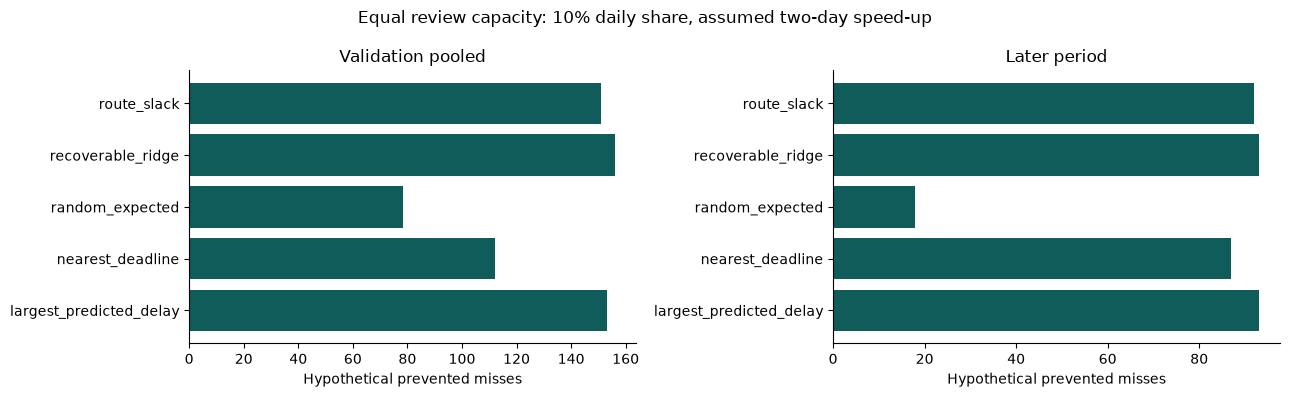

strategy,largest_predicted_delay,nearest_deadline,random_expected,recoverable_ridge,route_slack
assumed_days_saved,,,,,
1,63.0,61.0,11.44,63.0,61.0
2,93.0,87.0,17.93,93.0,92.0
3,119.0,106.0,22.79,119.0,116.0


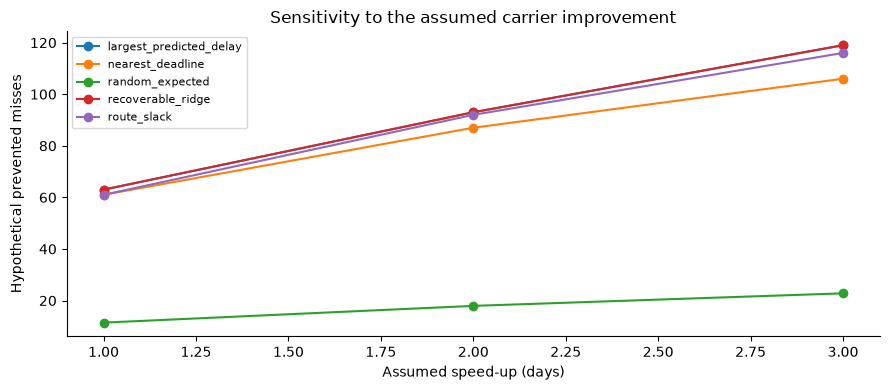

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, evaluation in zip(axes, ['Validation pooled', 'Later period']):
    part = comparison.loc[evaluation]
    ax.barh(part.index, part.hypothetical_prevented, color='#0F5C5A')
    ax.set(title=evaluation, xlabel='Hypothetical prevented misses')
fig.suptitle('Equal review capacity: 10% daily share, assumed two-day speed-up')
plt.tight_layout(); plt.show()
sensitivity = queues[queues.period.eq('test_descriptive') & queues.share.eq(.10)].pivot(
    index='assumed_days_saved', columns='strategy', values='hypothetical_prevented')
display(sensitivity.round(2))
ax = sensitivity.plot(marker='o')
ax.set(xlabel='Assumed speed-up (days)', ylabel='Hypothetical prevented misses', title='Sensitivity to the assumed carrier improvement')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()


**Interpretation.** At the 10% share with an assumed two-day speed-up, forecast ranking identifies 238 eventual late parcels in the later period, compared with 183 for nearest deadline and 225 for route slack. However, the corresponding hypothetical prevented misses are 93, 87 and 92. Finding more late parcels does not necessarily find substantially more recoverable parcels.

Across validation, forecast ranking gives 153 hypothetical recoveries versus 151 for route slack. The recovery-band alternative gives 156, but no improvement over forecast ranking in the later period. These small differences do not establish a robust winning intervention policy. Random counts are expectations and may be fractional.

This replay uses daily queues within the original purchase cohorts. It is not a full-marketplace staffing simulation, and unreviewed orders are not carried forward. Its population differs from Phase 2's monthly ranking and complete daily replay [3].


## 7. Feedback: actual regression tree configurations

The original full-comparison table used candidate names without all settings. The following table exposes every effective estimator parameter, including defaults, for the submitted tree, random forest and histogram gradient boosting candidates. Explicit tuning alternatives are shown separately. This records the original search; it does not claim a new tree-grid experiment.


In [9]:
configs = json.loads((RESULTS / 'submitted_tree_configurations.json').read_text())
display(pd.DataFrame([{'candidate': c['candidate'], 'estimator': c['estimator'],
                       'tuning_alternative': str(c['explicit_overrides'])} for c in configs]))
full_settings = pd.DataFrame({c['candidate']: c['effective_settings'] for c in configs}).fillna('—')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(full_settings.astype(str))


,candidate,estimator,tuning_alternative
0,tree_baseline,DecisionTreeRegressor,"{'max_depth': None, 'min_samples_leaf': 1}"
1,tree_depth6,DecisionTreeRegressor,"{'max_depth': 6, 'min_samples_leaf': 50}"
2,forest_leaf20,RandomForestRegressor,"{'max_depth': None, 'min_samples_leaf': 20}"
3,boost_baseline,HistGradientBoostingRegressor,{}
4,boost_slow,HistGradientBoostingRegressor,"{'learning_rate': 0.05, 'max_iter': 300, 'min_..."


,tree_baseline,tree_depth6,forest_leaf20,boost_baseline,boost_slow
ccp_alpha,0.0,0.0,0.0,—,—
criterion,squared_error,squared_error,squared_error,—,—
max_depth,—,6,—,—,—
max_features,—,—,sqrt,1.0,1.0
max_leaf_nodes,—,—,—,31,31
min_impurity_decrease,0.0,0.0,0.0,—,—
min_samples_leaf,1,50,20,20,40
min_samples_split,2,2,2,—,—
min_weight_fraction_leaf,0.0,0.0,0.0,—,—
monotonic_cst,—,—,—,—,—


## 8. Implications for the application

The handover contribution supplies **estimated remaining time, time left to the promise, estimated shortfall, and a route-history comparison**. It supports the order-detail view and a carrier-recovery check while preserving the original promise.

A risk ranking answers which parcels need attention; the forecast explains the estimated timing problem. A carrier must still establish available services, cost and achievable improvement. Already-missed promises belong in escalation/customer communication, not a prevention count.

Before presenting an uncertainty range or bias-corrected estimate, evaluate it using only earlier completed outcomes. Subtracting the entire test period's observed bias would use information unavailable when those predictions were made. Aggregate MAE is not an individual uncertainty interval.

**Current conclusion:** the handover forecast can inform review and quantify estimated shortfall. The evidence supports neither automatic expediting nor a measured financial benefit. Next work should evaluate time-valid uncertainty and bias adjustment, examine disagreement with route history, and integrate the estimate with the classification queue. A genuine impact evaluation would require recorded actions and a suitable comparison group.

## References

[1] [Submitted five-window regression metrics](../../Phase2/results/phase2/eta/cv_metrics.csv).

[2] [Handover features and fitting](../../Phase2/phase2_eta.py), [preprocessing and estimators](../../Phase2/phase2_regression.py), and [paired one-SE implementation](../../Phase2/phase2_selection.py).

[3] [Phase 2 report evidence map](../../Phase2/docs/report_evidence_map.md).

[4] [Analysis implementation](analyse.py) and generated [selection audit](results/selection_audit.json). New tables and plots in this notebook are computed from these fits and their order-level predictions. Project references support the calculations; they are not evidence of carrier intervention efficacy.
